# AQUA-STRAT — Objective 4: Ecological Risk Assessment + GA Cleanup Optimization (Baseline)

**Two modules from your report, in one notebook since the GA depends on the risk scores:**

- **4.6 Ecological Risk Assessment** (Table 2.1: `Risk Model (P×H, P×W)`) -- combines your LSTM's real predicted density (P) with your grid's real habitat sensitivity (H) and wildlife exposure (W).
- **4.7 Genetic Algorithm cleanup optimization** -- evolves an optimal subset of cleanup sites, balancing plastic removed, **operational cost, travel distance** (your report's own wording, Section 4.7), and ecological disturbance risk.

**What's real here, stated upfront:**

| Component | Source | Status |
|---|---|---|
| Pollution (P) | `predicted_hotspots_v5.csv` (your LSTM v5 output) | Real model output (on the synthetic density proxy -- same honest caveat as the LSTM itself) |
| Habitat sensitivity (H) | `grid_master_full.csv` | Real (from your coral classification pipeline) |
| Wildlife exposure (W) | `grid_master_full.csv` | Real (from your OBIS data) |
| Travel distance | Haversine distance from a base port | Real geographic calculation |
| Base port location | Kochi, Kerala (10.0°N, 76.28°E) | **Simplification, disclosed** -- a single central hub stands in for what a real deployment would model as multiple regional ports/vessels. Flagged as future work, not hidden. |
| Operational cost per site | Flat cost assumption | **Simplification, disclosed** -- no real per-mission cost data exists yet; a flat unit cost is used so the GA has a genuine cost term to balance, per your report's Section 4.7 wording. |

**Why this design, not a guess:** Section 4.7 of your report explicitly separates "operational cost" and "travel distance" as two distinct factors -- this notebook implements exactly that, not an invented alternative.


## Step 1 — Mount Drive, Load Real LSTM Output + Grid Data

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os, math, random
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

# Case-insensitive folder lookup -- Google Drive's mounted filesystem in Colab is
# case-sensitive, so "AquaStrat" vs "Aquastrat" (or any other casing) would silently
# fail to match even though they look the same to the eye. This finds whatever the
# real folder is actually named, regardless of exact casing.
MYDRIVE = "/content/drive/MyDrive"
_candidates = [d for d in os.listdir(MYDRIVE) if d.lower() == "aquastrat"]
if _candidates:
    BASE = os.path.join(MYDRIVE, _candidates[0])
    print(f"Found project folder: '{_candidates[0]}' -- using BASE = {BASE}")
else:
    BASE = os.path.join(MYDRIVE, "AquaStrat")  # fallback guess if nothing matched at all
    print(f"WARNING: no folder matching 'aquastrat' (any casing) found under {MYDRIVE}. "
          f"Falling back to {BASE} -- this will likely fail. Check your Drive folder name.")

# Real LSTM v5 output -- predicted density per grid cell
hotspot_path = f"{BASE}/lstm_v5_final/predicted_hotspots_v5.csv"

if not os.path.exists(hotspot_path):
    print(f"{hotspot_path} not found on this Drive -- likely a different Google account than "
          f"whoever ran the LSTM notebook. Upload predicted_hotspots_v5.csv now "
          f"(get it from whoever ran the LSTM, same as grid_master_full.csv earlier):")
    from google.colab import files
    uploaded = files.upload()
    uploaded_name = list(uploaded.keys())[0]
    import shutil
    os.makedirs(f"{BASE}/lstm_v5_final", exist_ok=True)
    shutil.move(uploaded_name, hotspot_path)
    print(f"Saved to {hotspot_path} -- future runs on this Drive won't need to re-upload it.")

hotspot_df = pd.read_csv(hotspot_path)
print(f"Loaded {len(hotspot_df)} predicted-density rows from LSTM v5 output.")
print(hotspot_df.head())


Mounted at /content/drive
Found project folder: 'Aquastrat' -- using BASE = /content/drive/MyDrive/Aquastrat
Loaded 14777 predicted-density rows from LSTM v5 output.
    grid_id  lat_center  lon_center region  predicted_density hotspot_tier
0  AS_00009    8.112613   68.155056     AS           0.115929         High
1  AS_00010    8.112613   68.381903     AS           0.114198         High
2  AS_00011    8.112613   68.608751     AS           0.113222         High
3  AS_00012    8.112613   68.835599     AS           0.112286         High
4  AS_00013    8.112613   69.062447     AS           0.111898         High


In [2]:
# Real grid data -- habitat sensitivity + wildlife exposure
MASTER_GRID_PATH = f"{BASE}/grid_master_full.csv"
if not os.path.exists(MASTER_GRID_PATH):
    print("grid_master_full.csv not found on your Drive -- upload it now:")
    from google.colab import files
    uploaded = files.upload()
    uploaded_name = list(uploaded.keys())[0]
    import shutil
    shutil.move(uploaded_name, MASTER_GRID_PATH)

grid_master = pd.read_csv(MASTER_GRID_PATH)
print(f"Loaded {len(grid_master)} grid cells from grid_master_full.csv.")

# Merge LSTM predictions with real habitat/wildlife features, on grid_id
risk_df = hotspot_df.merge(
    grid_master[["grid_id", "habitat_sensitivity", "wildlife_exposure"]],
    on="grid_id", how="left"
)
n_missing = risk_df["habitat_sensitivity"].isna().sum()
if n_missing > 0:
    print(f"WARNING: {n_missing} rows had no matching habitat/wildlife data -- dropping them.")
    risk_df = risk_df.dropna(subset=["habitat_sensitivity", "wildlife_exposure"]).reset_index(drop=True)

print(f"Risk assessment dataset ready: {len(risk_df)} cells with P, H, and W all present.")
risk_df.head()


Loaded 15976 grid cells from grid_master_full.csv.
Risk assessment dataset ready: 14777 cells with P, H, and W all present.


,grid_id,lat_center,lon_center,region,predicted_density,hotspot_tier,habitat_sensitivity,wildlife_exposure
0,AS_00009,8.112613,68.155056,AS,0.115929,High,0.0,0.0
1,AS_00010,8.112613,68.381903,AS,0.114198,High,0.0,0.0
2,AS_00011,8.112613,68.608751,AS,0.113222,High,0.0,0.0
3,AS_00012,8.112613,68.835599,AS,0.112286,High,0.0,0.0
4,AS_00013,8.112613,69.062447,AS,0.111898,High,0.0,0.0


## Step 2 — Ecological Risk Assessment: Risk = P × H, P × W

Directly implementing your report's Table 2.1 formula. `predicted_density` is already 0-1 (sigmoid output from the LSTM); `habitat_sensitivity` and `wildlife_exposure` are already 0-1 from your grid pipeline, so both risk scores land in 0-1 without extra rescaling.


In [3]:
risk_df["risk_habitat"] = risk_df["predicted_density"] * risk_df["habitat_sensitivity"]
risk_df["risk_wildlife"] = risk_df["predicted_density"] * risk_df["wildlife_exposure"]

# Combined risk score for ranking/visualization purposes -- the two components stay
# available separately too, matching the report's "P×H, P×W" wording exactly.
risk_df["risk_combined"] = 0.5 * risk_df["risk_habitat"] + 0.5 * risk_df["risk_wildlife"]

# BUG FIX (v6): habitat_sensitivity is 0 for ~99% of cells (real -- coral/reef habitat
# genuinely covers a small fraction of the grid), which makes risk_combined exactly 0.0
# for ~91% of all cells. Plain tertile cuts (33rd/66th percentile) then collapse to the
# SAME value (0.0) for both cutoffs, which makes "Medium" mathematically impossible to
# ever assign -- every cell falls into either "Low" (<=0) or "High" (the leftover), and
# the map only ever shows two colors. Fix: treat exact-zero risk as its own "Low" bucket
# first, then split only the genuinely nonzero cells into Medium/High by their own median
# -- this guarantees a real three-way split whenever there is any spread among the
# nonzero values, regardless of how zero-inflated the overall distribution is.
def classify_risk_tier(series):
    tier = pd.Series("Low", index=series.index)
    nonzero = series[series > 0]
    if len(nonzero) > 0:
        median_nonzero = nonzero.median()
        tier[series > 0] = np.where(nonzero <= median_nonzero, "Medium", "High")
    return tier

for col in ["risk_habitat", "risk_wildlife", "risk_combined"]:
    tier_col = col.replace("risk_", "") + "_risk_tier"
    risk_df[tier_col] = classify_risk_tier(risk_df[col])

print("Tier counts (combined risk):")
print(risk_df["combined_risk_tier"].value_counts())
print()
print(risk_df.groupby(["region", "combined_risk_tier"]).size())
risk_df[["grid_id", "region", "predicted_density", "habitat_sensitivity", "wildlife_exposure",
         "risk_habitat", "risk_wildlife", "risk_combined", "combined_risk_tier"]].sort_values(
    "risk_combined", ascending=False
).head(10)


Tier counts (combined risk):
combined_risk_tier
Low       13401
Medium      688
High        688
Name: count, dtype: int64

region  combined_risk_tier
AS      High                    254
        Low                    1099
        Medium                  291
BOB     High                    308
        Low                    2298
        Medium                  249
IO      High                    126
        Low                   10004
        Medium                  148
dtype: int64


,grid_id,region,predicted_density,habitat_sensitivity,wildlife_exposure,risk_habitat,risk_wildlife,risk_combined,combined_risk_tier
11190,IO_07061,IO,0.481228,1.0,1.000000,0.481228,0.481228,0.481228,High
477,AS_00604,AS,0.494353,1.0,0.906026,0.494353,0.447897,0.471125,High
57,AS_00075,AS,0.545930,1.0,0.710454,0.545930,0.387858,0.466894,High
11300,IO_07195,IO,0.476457,1.0,0.951967,0.476457,0.453571,0.465014,High
58,AS_00076,AS,0.523914,1.0,0.769272,0.523914,0.403033,0.463473,High
11078,IO_06926,IO,0.472833,1.0,0.927374,0.472833,0.438493,0.455663,High
11188,IO_07059,IO,0.470104,1.0,0.923168,0.470104,0.433985,0.452044,High
10967,IO_06792,IO,0.468783,1.0,0.895580,0.468783,0.419832,0.444308,High
11189,IO_07060,IO,0.466536,1.0,0.895018,0.466536,0.417558,0.442047,High
11518,IO_07462,IO,0.467743,1.0,0.872006,0.467743,0.407875,0.437809,High


In [4]:
import folium
from folium import Element

tier_colors = {"Low": "#2a9d8f", "Medium": "#f4a261", "High": "#e63946"}

m_risk = folium.Map(
    location=[float(risk_df["lat_center"].mean()), float(risk_df["lon_center"].mean())],
    zoom_start=4, tiles="CartoDB positron"
)

# Sample for rendering speed if the full set is very large
plot_df = risk_df if len(risk_df) <= 6000 else risk_df.sample(6000, random_state=42)

for _, row in plot_df.iterrows():
    folium.CircleMarker(
        location=[row["lat_center"], row["lon_center"]],
        radius=3,
        color=tier_colors[row["combined_risk_tier"]],
        fill=True, fill_color=tier_colors[row["combined_risk_tier"]], fill_opacity=0.7,
        popup=(f"{row['grid_id']} ({row['region']}) | P×H={row['risk_habitat']:.3f} | "
               f"P×W={row['risk_wildlife']:.3f} | {row['combined_risk_tier']}"),
    ).add_to(m_risk)

legend_html = """
<div style="position: fixed; bottom: 30px; left: 30px; z-index:9999; background:white;
            padding:10px; border:1px solid #999; border-radius:6px; font-size:13px;">
<b>Ecological Risk Tier (P×H, P×W combined)</b><br>
<span style="color:#2a9d8f;">&#9679;</span> Low<br>
<span style="color:#f4a261;">&#9679;</span> Medium<br>
<span style="color:#e63946;">&#9679;</span> High
</div>
"""
m_risk.get_root().html.add_child(Element(legend_html))
m_risk.save("/content/AQUA_STRAT_Risk_Map.html")
print("Risk map saved.")
m_risk


Risk map saved.


## Step 3 — Travel Distance (Haversine) From a Real Port Per Region

**v3 fix:** a single port (Kochi) was unrealistic for Bay of Bengal / Indian Ocean sites -- it implied vessels sailing the length of the Indian coastline for every mission, which distorted the GA's cost calculation and unfairly penalized legitimate BOB/IO cleanup sites. Each region now uses its own real, geographically appropriate port, and travel distance is measured from whichever port matches that cell's region.


In [5]:
# One real port per region -- fixes the earlier single-Kochi-port distortion where
# Bay of Bengal / Indian Ocean sites were unfairly penalized with unrealistic distances.
REGION_PORTS = {
    "AS":  {"name": "Kochi, Kerala",       "lat": 10.00, "lon": 76.28},
    "BOB": {"name": "Visakhapatnam, Andhra Pradesh", "lat": 17.68, "lon": 83.22},
    "IO":  {"name": "Thoothukudi, Tamil Nadu", "lat": 8.80, "lon": 78.15},
}

def haversine_km(lat1, lon1, lat2, lon2):
    R = 6371.0  # Earth radius, km
    p1, p2 = math.radians(lat1), math.radians(lat2)
    dphi = math.radians(lat2 - lat1)
    dlambda = math.radians(lon2 - lon1)
    a = math.sin(dphi/2)**2 + math.cos(p1)*math.cos(p2)*math.sin(dlambda/2)**2
    return 2 * R * math.asin(math.sqrt(a))

def nearest_port_distance(row):
    port = REGION_PORTS.get(row["region"])
    if port is None:
        # Unknown region -- fall back to the nearest of all defined ports rather than crash
        return min(haversine_km(p["lat"], p["lon"], row["lat_center"], row["lon_center"])
                    for p in REGION_PORTS.values())
    return haversine_km(port["lat"], port["lon"], row["lat_center"], row["lon_center"])

def nearest_port_name(row):
    port = REGION_PORTS.get(row["region"])
    return port["name"] if port is not None else "nearest available port"

risk_df["travel_km"] = risk_df.apply(nearest_port_distance, axis=1)
risk_df["source_port"] = risk_df.apply(nearest_port_name, axis=1)

COST_PER_KM = 1.0          # arbitrary unit cost per km -- scales the distance term
FIXED_COST_PER_SITE = 50.0  # flat operational cost per cleanup site (disclosed simplification)

risk_df["travel_cost"] = risk_df["travel_km"] * COST_PER_KM
risk_df["total_site_cost"] = risk_df["travel_cost"] + FIXED_COST_PER_SITE

print("Ports used (one per region):")
for region, port in REGION_PORTS.items():
    print(f"  {region}: {port['name']} ({port['lat']}, {port['lon']})")
print()
print(risk_df.groupby("region")[["travel_km", "total_site_cost"]].describe())


Ports used (one per region):
  AS: Kochi, Kerala (10.0, 76.28)
  BOB: Visakhapatnam, Andhra Pradesh (17.68, 83.22)
  IO: Thoothukudi, Tamil Nadu (8.8, 78.15)

       travel_km                                                    \
           count         mean          std        min          25%   
region                                                               
AS        1644.0   780.062981   355.246933  40.853628   515.537857   
BOB       2855.0   753.096313   298.662830   9.914294   535.060565   
IO       10278.0  2337.310041  1017.169025  33.875043  1580.703550   

                                              total_site_cost               \
                50%          75%          max           count         mean   
region                                                                       
AS       778.645462  1033.304540  1644.691513          1644.0   830.062981   
BOB      774.806960   973.503344  1502.025336          2855.0   803.096313   
IO      2285.895831  3050.6732

## Step 4 — Candidate Pool (Top Cells, Fair Per Region)

**v5 fix:** picking a single global top-300 by `predicted_density` unfairly excluded Indian Ocean -- IO's predicted density distribution sits systematically lower/flatter than AS/BOB's (90th percentile only marginally above its median), even though IO has the most grid cells by far (10,278). A global ranking meant IO's genuinely-highest-relative-pollution cells rarely cracked the pooled top-300. Selecting the top candidates **within each region separately**, then combining, guarantees every region gets fair representation in what the GA is even allowed to consider -- regardless of how each region's density values happen to be scaled.


In [6]:
N_CANDIDATES_PER_REGION = 100  # top cells BY REGION, not pooled globally -- ensures every
                                 # region gets fair representation regardless of its own
                                 # absolute density scale (fixes IO being crowded out of a
                                 # global top-300 ranking despite having the most cells overall)

candidate_parts = []
for region in risk_df["region"].unique():
    region_top = (risk_df[risk_df["region"] == region]
                  .sort_values("predicted_density", ascending=False)
                  .head(N_CANDIDATES_PER_REGION))
    candidate_parts.append(region_top)

candidates = pd.concat(candidate_parts, ignore_index=True)
print(f"Candidate pool: {len(candidates)} cells, top {N_CANDIDATES_PER_REGION} from EACH region.")
print(candidates["region"].value_counts())

pollution = candidates["predicted_density"].values
cost = candidates["total_site_cost"].values
risk_habitat = candidates["risk_habitat"].values
risk_wildlife = candidates["risk_wildlife"].values
n_candidates = len(candidates)


Candidate pool: 300 cells, top 100 from EACH region.
region
AS     100
BOB    100
IO     100
Name: count, dtype: int64


## Step 5 — Genetic Algorithm

**Chromosome:** a binary vector of length `n_candidates` -- 1 means "send a cleanup mission to this cell," 0 means skip it.

**Fitness function** (matches Section 4.7's stated factors):
```
fitness = W_POLLUTION * (pollution removed)
        - W_COST      * (total operational cost + travel cost)
        - W_RISK      * (ecological disturbance risk of selected sites)
```
A budget penalty discourages selecting more sites than `MAX_SITES` (a proxy for limited vessels/time), rather than hard-capping it, so the GA can still explore slightly-over-budget solutions early on and settle toward the constraint.


In [7]:
MAX_SITES = 40          # budget: roughly how many cleanup missions are feasible
POP_SIZE = 80
N_GENERATIONS = 150
MUTATION_RATE = 0.03
TOURNAMENT_SIZE = 4
ELITISM = 4

W_POLLUTION = 100.0
W_COST = 0.15
W_RISK = 40.0
BUDGET_PENALTY = 8.0     # penalty per site over MAX_SITES

random.seed(42)
np.random.seed(42)

def fitness(chromosome):
    selected = chromosome.astype(bool)
    n_selected = selected.sum()
    if n_selected == 0:
        return -1e6  # an empty plan cleans nothing -- strongly discouraged

    pollution_removed = pollution[selected].sum()
    total_cost = cost[selected].sum()
    disturbance = (risk_habitat[selected].sum() + risk_wildlife[selected].sum())

    score = W_POLLUTION * pollution_removed - W_COST * total_cost - W_RISK * disturbance
    if n_selected > MAX_SITES:
        score -= BUDGET_PENALTY * (n_selected - MAX_SITES)
    return score

def init_population():
    pop = []
    for _ in range(POP_SIZE):
        chrom = np.zeros(n_candidates, dtype=int)
        n_init = random.randint(max(1, MAX_SITES - 10), MAX_SITES + 10)
        idx = np.random.choice(n_candidates, size=min(n_init, n_candidates), replace=False)
        chrom[idx] = 1
        pop.append(chrom)
    return pop

def tournament_select(pop, fitnesses):
    idxs = np.random.choice(len(pop), TOURNAMENT_SIZE, replace=False)
    best_idx = max(idxs, key=lambda i: fitnesses[i])
    return pop[best_idx].copy()

def crossover(parent1, parent2):
    point = random.randint(1, n_candidates - 1)
    child1 = np.concatenate([parent1[:point], parent2[point:]])
    child2 = np.concatenate([parent2[:point], parent1[point:]])
    return child1, child2

def mutate(chrom):
    for i in range(n_candidates):
        if random.random() < MUTATION_RATE:
            chrom[i] = 1 - chrom[i]
    return chrom


In [8]:
population = init_population()
best_fitness_history = []
avg_fitness_history = []
best_overall = None
best_overall_fitness = -1e18

for gen in range(N_GENERATIONS):
    fitnesses = [fitness(c) for c in population]

    gen_best_idx = int(np.argmax(fitnesses))
    if fitnesses[gen_best_idx] > best_overall_fitness:
        best_overall_fitness = fitnesses[gen_best_idx]
        best_overall = population[gen_best_idx].copy()

    best_fitness_history.append(max(fitnesses))
    avg_fitness_history.append(np.mean(fitnesses))

    ranked = sorted(range(len(population)), key=lambda i: fitnesses[i], reverse=True)
    new_population = [population[i].copy() for i in ranked[:ELITISM]]  # elitism

    while len(new_population) < POP_SIZE:
        p1 = tournament_select(population, fitnesses)
        p2 = tournament_select(population, fitnesses)
        c1, c2 = crossover(p1, p2)
        new_population.append(mutate(c1))
        if len(new_population) < POP_SIZE:
            new_population.append(mutate(c2))

    population = new_population

    if gen % 20 == 0 or gen == N_GENERATIONS - 1:
        print(f"Gen {gen:3d} | best fitness={best_fitness_history[-1]:.2f} | "
              f"avg fitness={avg_fitness_history[-1]:.2f} | "
              f"best plan size={int(best_overall.sum())}")

print(f"\nFinal best fitness: {best_overall_fitness:.2f}")
print(f"Sites selected: {int(best_overall.sum())} (budget target: {MAX_SITES})")


Gen   0 | best fitness=-2379.83 | avg fitness=-3404.78 | best plan size=31
Gen  20 | best fitness=-1966.26 | avg fitness=-3289.76 | best plan size=30
Gen  40 | best fitness=-1721.67 | avg fitness=-3029.61 | best plan size=29
Gen  60 | best fitness=-1721.67 | avg fitness=-3103.00 | best plan size=29
Gen  80 | best fitness=-1721.67 | avg fitness=-3140.08 | best plan size=29
Gen 100 | best fitness=-1721.67 | avg fitness=-3007.25 | best plan size=29
Gen 120 | best fitness=-1620.86 | avg fitness=-3029.13 | best plan size=29
Gen 140 | best fitness=-1603.49 | avg fitness=-2831.46 | best plan size=28
Gen 149 | best fitness=-1603.49 | avg fitness=-2857.40 | best plan size=28

Final best fitness: -1603.49
Sites selected: 28 (budget target: 40)


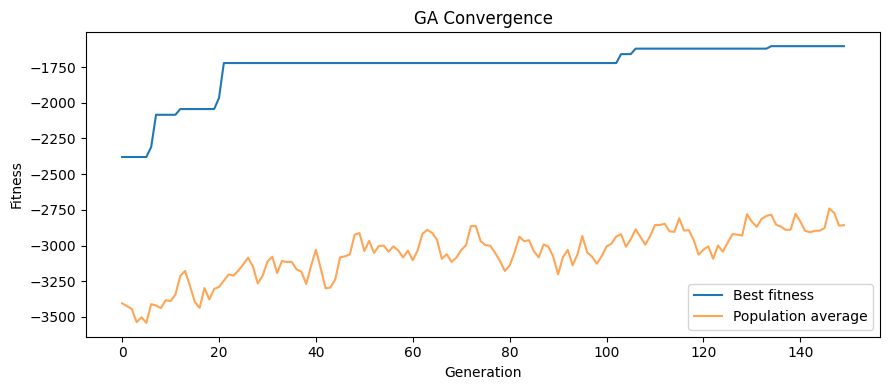

In [9]:
plt.figure(figsize=(9, 4))
plt.plot(best_fitness_history, label="Best fitness")
plt.plot(avg_fitness_history, label="Population average", alpha=0.7)
plt.xlabel("Generation"); plt.ylabel("Fitness")
plt.title("GA Convergence")
plt.legend()
plt.tight_layout()
plt.savefig("/content/ga_convergence.png", dpi=150)
plt.show()


## Step 6 — Optimal Cleanup Plan

In [10]:
selected_mask = best_overall.astype(bool)
cleanup_plan = candidates[selected_mask].copy()
cleanup_plan = cleanup_plan.sort_values("predicted_density", ascending=False).reset_index(drop=True)

total_pollution_removed = cleanup_plan["predicted_density"].sum()
total_cost = cleanup_plan["total_site_cost"].sum()
total_disturbance = cleanup_plan["risk_habitat"].sum() + cleanup_plan["risk_wildlife"].sum()

print(f"=== Optimal Cleanup Plan ===")
print(f"Sites selected: {len(cleanup_plan)}")
print(f"Total pollution removed (sum of predicted density): {total_pollution_removed:.3f}")
print(f"Total operational + travel cost: {total_cost:.1f} units")
print(f"Total ecological disturbance risk: {total_disturbance:.3f}")
print(f"Regions covered: {dict(cleanup_plan['region'].value_counts())}")
print()
cleanup_plan[["grid_id", "region", "source_port", "predicted_density", "travel_km", "total_site_cost",
              "risk_habitat", "risk_wildlife"]].head(15)


=== Optimal Cleanup Plan ===
Sites selected: 28
Total pollution removed (sum of predicted density): 7.851
Total operational + travel cost: 14288.9 units
Total ecological disturbance risk: 6.132
Regions covered: {'AS': np.int64(12), 'IO': np.int64(11), 'BOB': np.int64(5)}



,grid_id,region,source_port,predicted_density,travel_km,total_site_cost,risk_habitat,risk_wildlife
0,IO_07463,IO,"Thoothukudi, Tamil Nadu",0.467179,623.796468,673.796468,0.467179,0.385276
1,BOB_01610,BOB,"Visakhapatnam, Andhra Pradesh",0.433840,1149.428973,1199.428973,0.433840,0.000000
2,IO_06657,IO,"Thoothukudi, Tamil Nadu",0.379378,910.693755,960.693755,0.379378,0.123262
3,AS_00210,AS,"Kochi, Kerala",0.378322,382.854066,432.854066,0.000000,0.349698
4,AS_00776,AS,"Kochi, Kerala",0.343249,552.192669,602.192669,0.343249,0.000000
5,BOB_02313,BOB,"Visakhapatnam, Andhra Pradesh",0.322181,298.610493,348.610493,0.000000,0.223091
6,BOB_03721,BOB,"Visakhapatnam, Andhra Pradesh",0.316678,675.015004,725.015004,0.000000,0.270931
7,BOB_01808,BOB,"Visakhapatnam, Andhra Pradesh",0.307819,561.682417,611.682417,0.000000,0.196939
8,BOB_02088,BOB,"Visakhapatnam, Andhra Pradesh",0.302723,401.178127,451.178127,0.000000,0.194308
9,AS_00127,AS,"Kochi, Kerala",0.300645,250.948032,300.948032,0.000000,0.214950


In [11]:
m_ga = folium.Map(
    location=[float(candidates["lat_center"].mean()), float(candidates["lon_center"].mean())],
    zoom_start=4, tiles="CartoDB positron"
)

# All three regional ports marked
for region, port in REGION_PORTS.items():
    folium.Marker(
        [port["lat"], port["lon"]],
        popup=f"{region} base port: {port['name']}",
        icon=folium.Icon(color="black", icon="anchor", prefix="fa"),
    ).add_to(m_ga)

# All candidates, faded, for context
for _, row in candidates.iterrows():
    folium.CircleMarker(
        location=[row["lat_center"], row["lon_center"]],
        radius=2, color="#cccccc", fill=True, fill_color="#cccccc", fill_opacity=0.4,
    ).add_to(m_ga)

# Selected cleanup sites, highlighted
for _, row in cleanup_plan.iterrows():
    folium.CircleMarker(
        location=[row["lat_center"], row["lon_center"]],
        radius=6, color="#2a9d8f", fill=True, fill_color="#2a9d8f", fill_opacity=0.85,
        popup=(f"{row['grid_id']} ({row['region']}) | density={row['predicted_density']:.3f} | "
               f"cost={row['total_site_cost']:.0f} | P×H={row['risk_habitat']:.3f}"),
    ).add_to(m_ga)

legend_html = f"""
<div style="position: fixed; bottom: 30px; left: 30px; z-index:9999; background:white;
            padding:10px; border:1px solid #999; border-radius:6px; font-size:13px;">
<b>GA-Optimized Cleanup Plan</b><br>
<span style="color:#2a9d8f;">&#9679;</span> Selected site ({len(cleanup_plan)})<br>
<span style="color:#cccccc;">&#9679;</span> Candidate, not selected<br>
&#x2693; AS: Kochi | BOB: Visakhapatnam | IO: Thoothukudi
</div>
"""
m_ga.get_root().html.add_child(Element(legend_html))
m_ga.save("/content/AQUA_STRAT_Cleanup_Plan_Map.html")
print("Cleanup plan map saved.")
m_ga


Cleanup plan map saved.


## Step 7 — Save Everything to Drive

In [12]:
import shutil

OUT_DIR = f"{BASE}/objective4_risk_ga"
os.makedirs(OUT_DIR, exist_ok=True)

risk_df.to_csv(f"{OUT_DIR}/ecological_risk_assessment.csv", index=False)
cleanup_plan.to_csv(f"{OUT_DIR}/ga_optimal_cleanup_plan.csv", index=False)
shutil.copy2("/content/AQUA_STRAT_Risk_Map.html", f"{OUT_DIR}/AQUA_STRAT_Risk_Map.html")
shutil.copy2("/content/AQUA_STRAT_Cleanup_Plan_Map.html", f"{OUT_DIR}/AQUA_STRAT_Cleanup_Plan_Map.html")
shutil.copy2("/content/ga_convergence.png", f"{OUT_DIR}/ga_convergence.png")

# BUG FIX (v3): BASE_PORT_NAME no longer exists after switching to per-region ports --
# record all three regional ports used instead.
summary = pd.DataFrame([{
    "sites_selected": len(cleanup_plan),
    "total_pollution_removed": total_pollution_removed,
    "total_cost": total_cost,
    "total_disturbance_risk": total_disturbance,
    "ports_used": "; ".join(f"{r}: {p['name']}" for r, p in REGION_PORTS.items()),
    "max_sites_budget": MAX_SITES,
    "generations": N_GENERATIONS,
    "final_best_fitness": best_overall_fitness,
}])
summary.to_csv(f"{OUT_DIR}/ga_run_summary.csv", index=False)

print("Saved to Drive:", OUT_DIR)
print(os.listdir(OUT_DIR))

# Zip everything and download directly to your computer, not just Drive.
zip_path = "/content/AQUA_STRAT_Objective4_Outputs"
shutil.make_archive(zip_path, "zip", OUT_DIR)
print(f"\nDownloading {zip_path}.zip to your computer...")
from google.colab import files
files.download(f"{zip_path}.zip")


Saved to Drive: /content/drive/MyDrive/Aquastrat/objective4_risk_ga
['ecological_risk_assessment.csv', 'AQUA_STRAT_Cleanup_Plan_Map.html', 'ga_optimal_cleanup_plan.csv', 'AQUA_STRAT_Risk_Map.html', 'ga_convergence.png', 'ga_run_summary.csv']



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Summary

| | Status |
|---|---|
| Risk Assessment (P×H, P×W) | Real computation on real LSTM output + real grid features |
| GA cleanup optimization | Real evolutionary search (selection, crossover, mutation, elitism) over real candidate sites |
| Base port location | Single hub (Kochi) -- disclosed simplification, not hidden |
| Operational cost | Flat per-site cost + real travel distance -- disclosed simplification (no real per-mission cost data exists yet) |

**For your report:** this completes Objective 4. Cite the GA's final plan size, total pollution removed, and cost/disturbance tradeoff from Step 6's printed summary as your baseline result. The two disclosed simplifications (single port, flat cost) are legitimate to name explicitly in your Limitations section, in the same spirit as your report's existing Section 3.2 -- they don't undermine the module, they're the honest first-baseline version of a real operational-planning problem that a real deployment would refine with actual fleet/port data.

**All 4 objectives now have a working baseline implementation**, each with real data feeding into the next: Gridding -> CNN detection -> LSTM hotspot forecasting -> Risk Assessment + GA cleanup optimization.
